# LazySlide Skill Iteration Validation Supplement

Notebook execution entrypoint for regenerating the OmicOS_10 supplementary validation tables and figures as separate subfigures.


## Setup


In [1]:
from pathlib import Path
import sys

from IPython.display import Image, display

PANEL_DISPLAY_WIDTH = 850
COMPOSITE_DISPLAY_WIDTH = 1050

cwd = Path.cwd().resolve()
project_root = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "OmicOS_10" / "scripts" / "build_skill_iteration_validation_supplement.py").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate OmicOS project root from the current notebook working directory.")

script_dir = project_root / "OmicOS_10" / "scripts"
if str(script_dir) not in sys.path:
    sys.path.insert(0, str(script_dir))

from build_skill_iteration_validation_supplement import (
    COMPOSITE_FIGSIZE as DEFAULT_COMPOSITE_FIGSIZE,
    PANEL_FIGSIZE as DEFAULT_PANEL_FIGSIZE,
    FIG_DIR,
    PANEL_DIR,
    build_edit_history,
    build_evidence_sources,
    build_final_validation_report,
    build_iteration_trace,
    ensure_dirs,
    plot_edit_history,
    plot_score_trace,
    plot_validation_matrix,
    plot_validation_summary,
    save_composite,
    save_panel,
    save_table_outputs,
    setup_style,
)

PANEL_FIGSIZE = DEFAULT_PANEL_FIGSIZE
COMPOSITE_FIGSIZE = DEFAULT_COMPOSITE_FIGSIZE


In [2]:
import omicverse as ov
import scanpy as sc
import matplotlib.pyplot as plt
ov.plot_set(font_path='Arial')
sc.settings.set_figure_params(dpi=300, vector_friendly=True)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams.update({
    'font.size': 18,
    'axes.titlesize': 18,
    'axes.labelsize': 18,
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    'legend.fontsize': 18,
})


/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early

🔬 Starting plot initialization...
Using already downloaded Arial font from: /tmp/omicverse_arial.ttf
Registered as: Arial
🧬 Detecting GPU devices…
✅ NVIDIA CUDA GPUs detected: 8
    • [CUDA 0] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 1] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 2] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 3] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 4] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 5] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 6] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 7] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__ 

## Build Tables


In [3]:
ensure_dirs()
setup_style()

tables = {
    "trace": build_iteration_trace(),
    "history": build_edit_history(),
    "report": build_final_validation_report(),
    "sources": build_evidence_sources(),
}
save_table_outputs(tables)
{name: len(frame) for name, frame in tables.items()}


{'trace': 8, 'history': 10, 'report': 6, 'sources': 15}

In [4]:
PANEL_FIGSIZE

(12, 7.5)

## Subfigure A: Score Trace


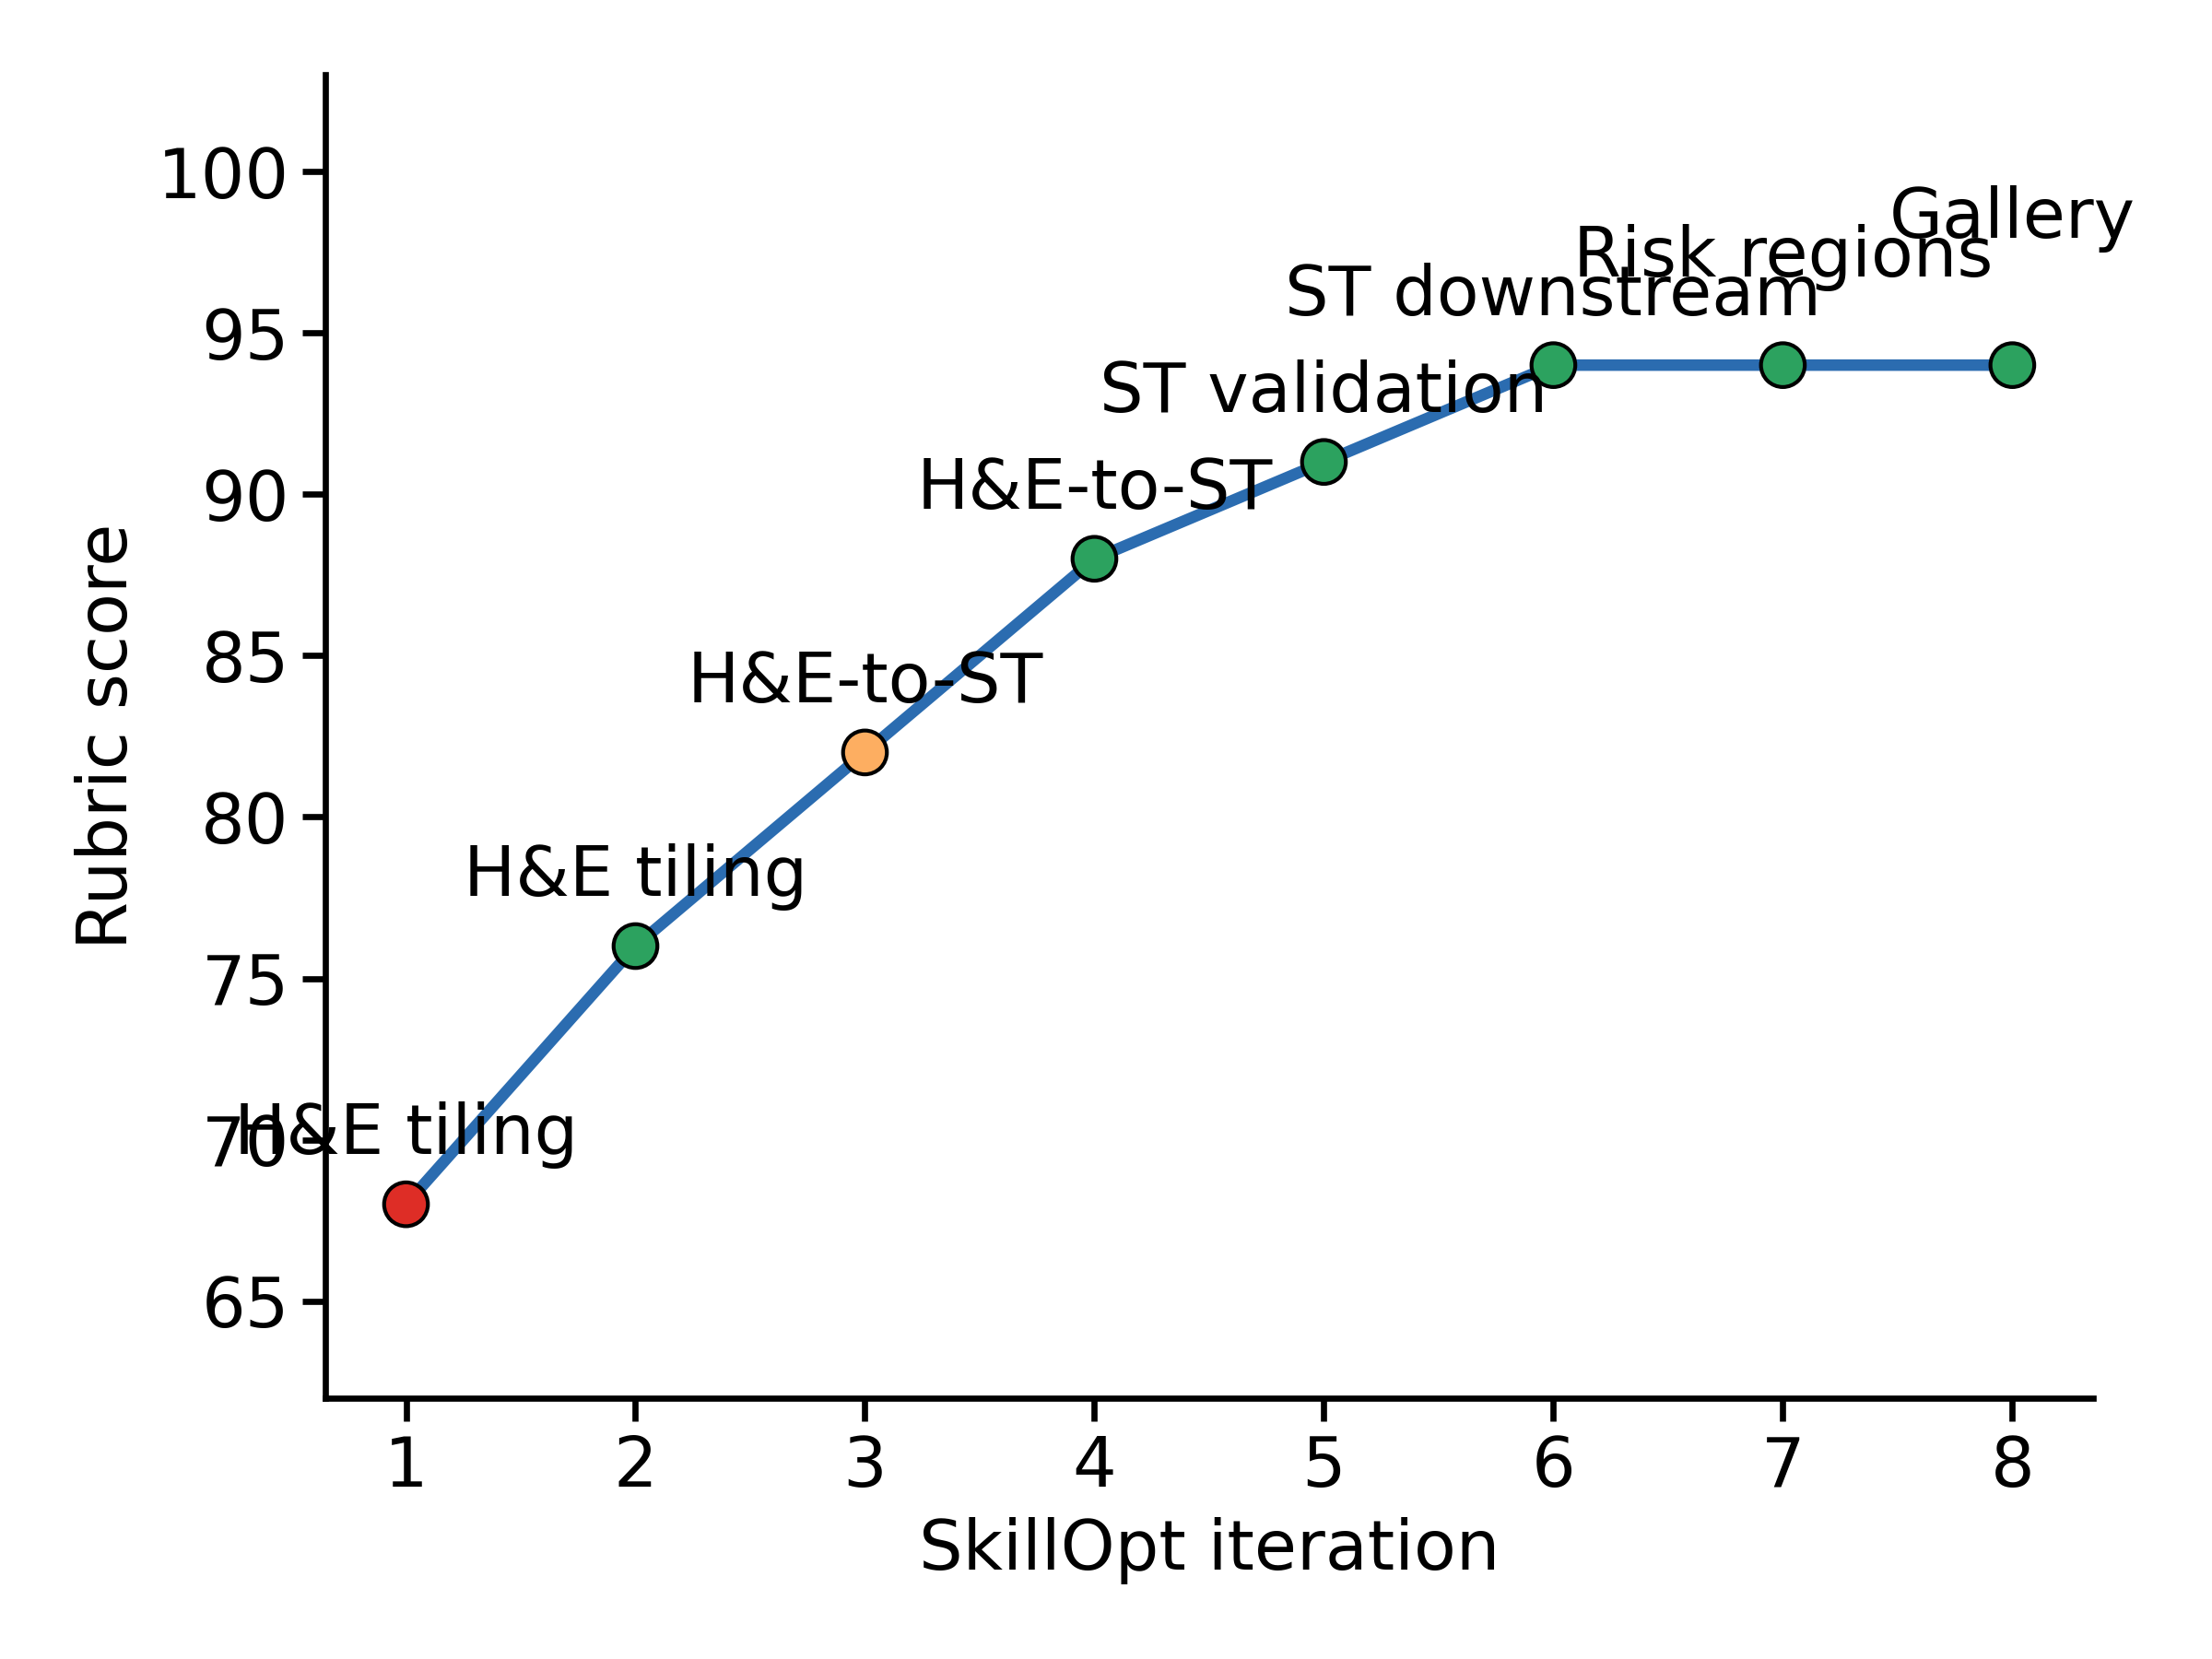

In [5]:
save_panel("supp_skill_iter_A_score_trace", plot_score_trace, tables["trace"], figsize=(8,6,))
display(Image(filename=str(PANEL_DIR / "supp_skill_iter_A_score_trace.png"), width=PANEL_DISPLAY_WIDTH))


## Subfigure B: Edit History


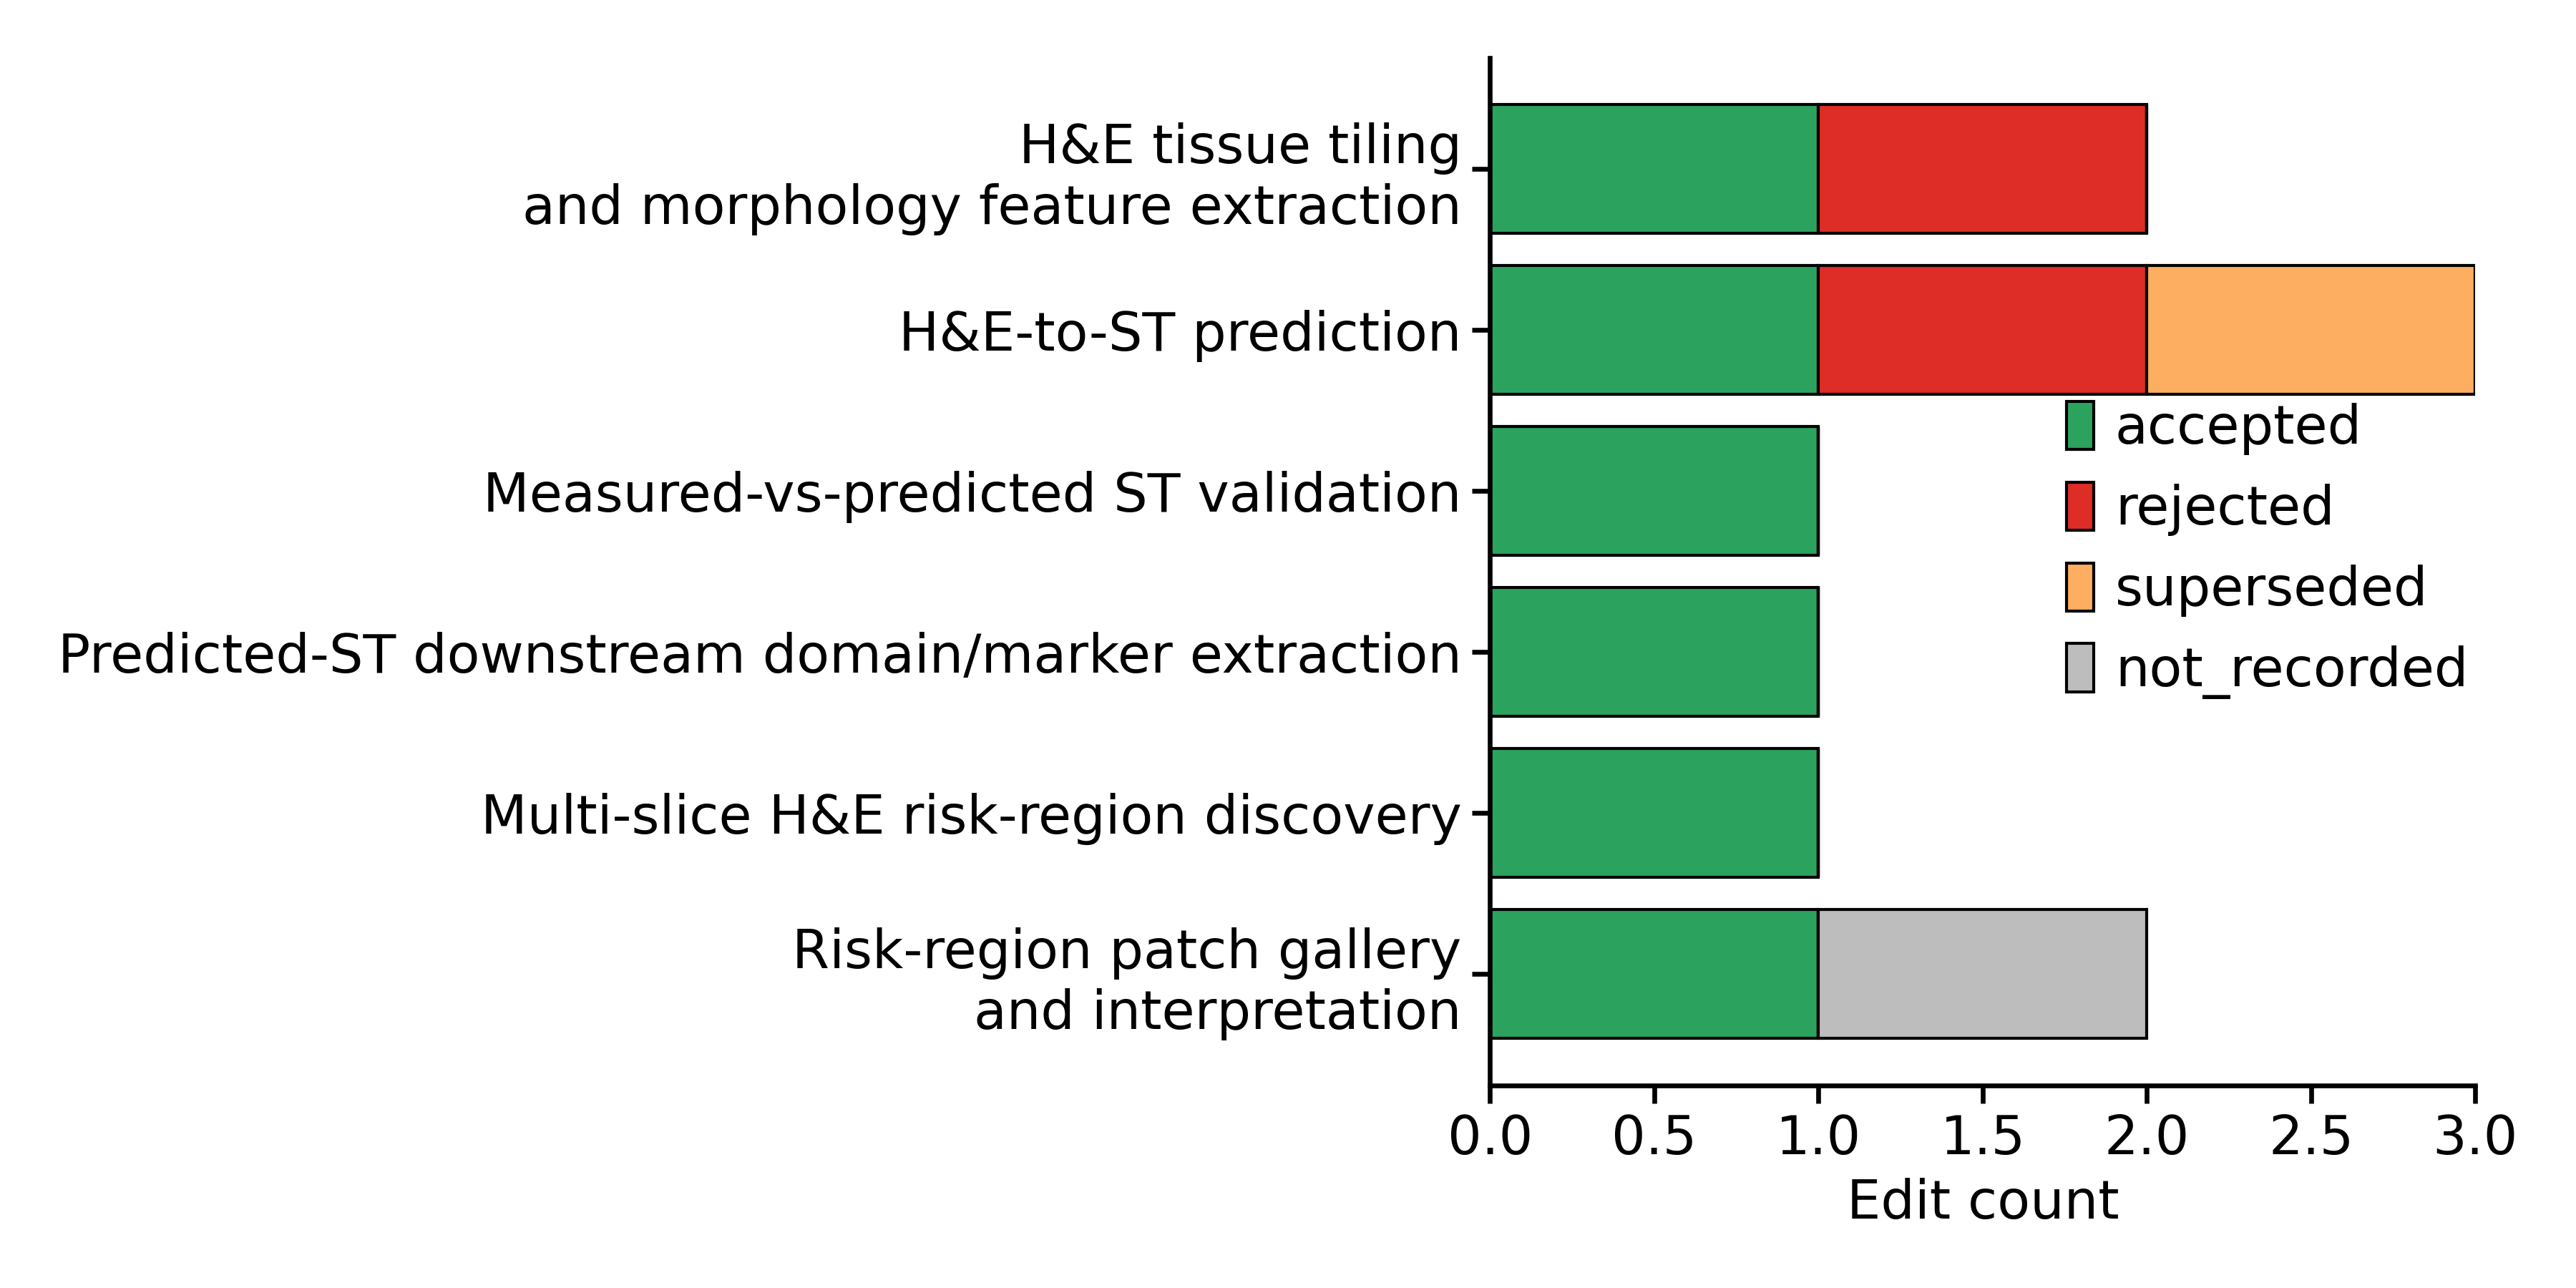

In [6]:
save_panel("supp_skill_iter_B_edit_history", plot_edit_history, tables["history"], figsize=(12,6))
display(Image(filename=str(PANEL_DIR / "supp_skill_iter_B_edit_history.png"), width=PANEL_DISPLAY_WIDTH))


## Subfigure C: Validation Matrix


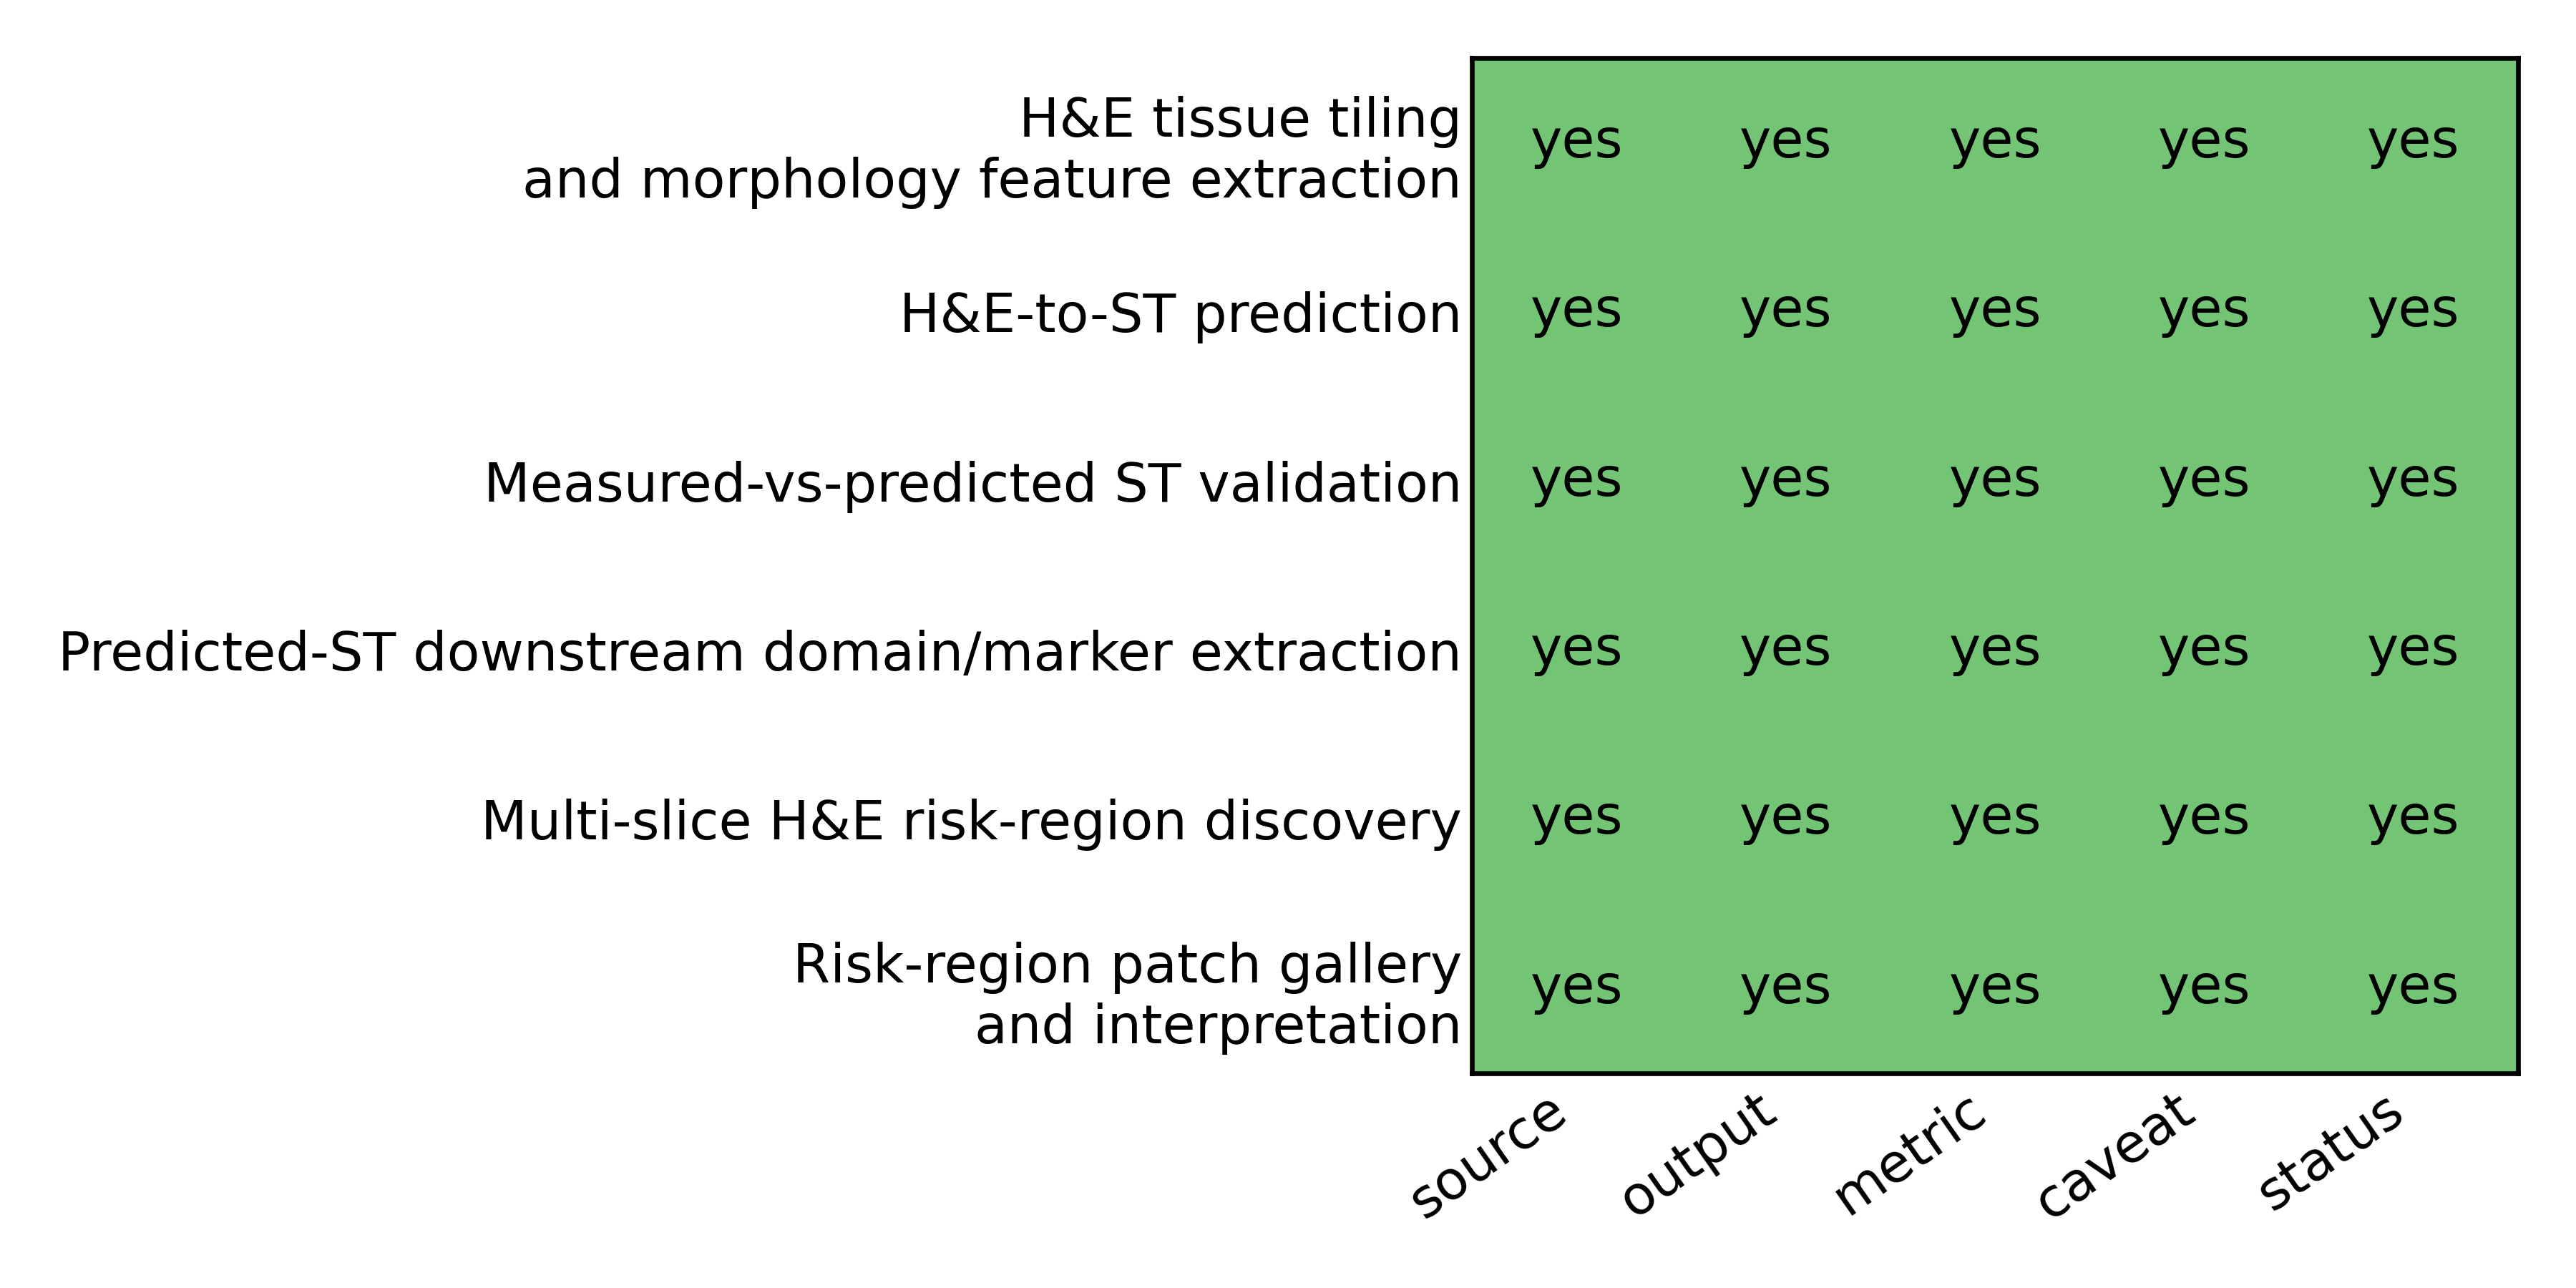

In [7]:
save_panel("supp_skill_iter_C_validation_matrix", plot_validation_matrix, tables["report"], tables["sources"], figsize=(12,6))
display(Image(filename=str(PANEL_DIR / "supp_skill_iter_C_validation_matrix.png"), width=PANEL_DISPLAY_WIDTH))


## Subfigure D: Validation Summary


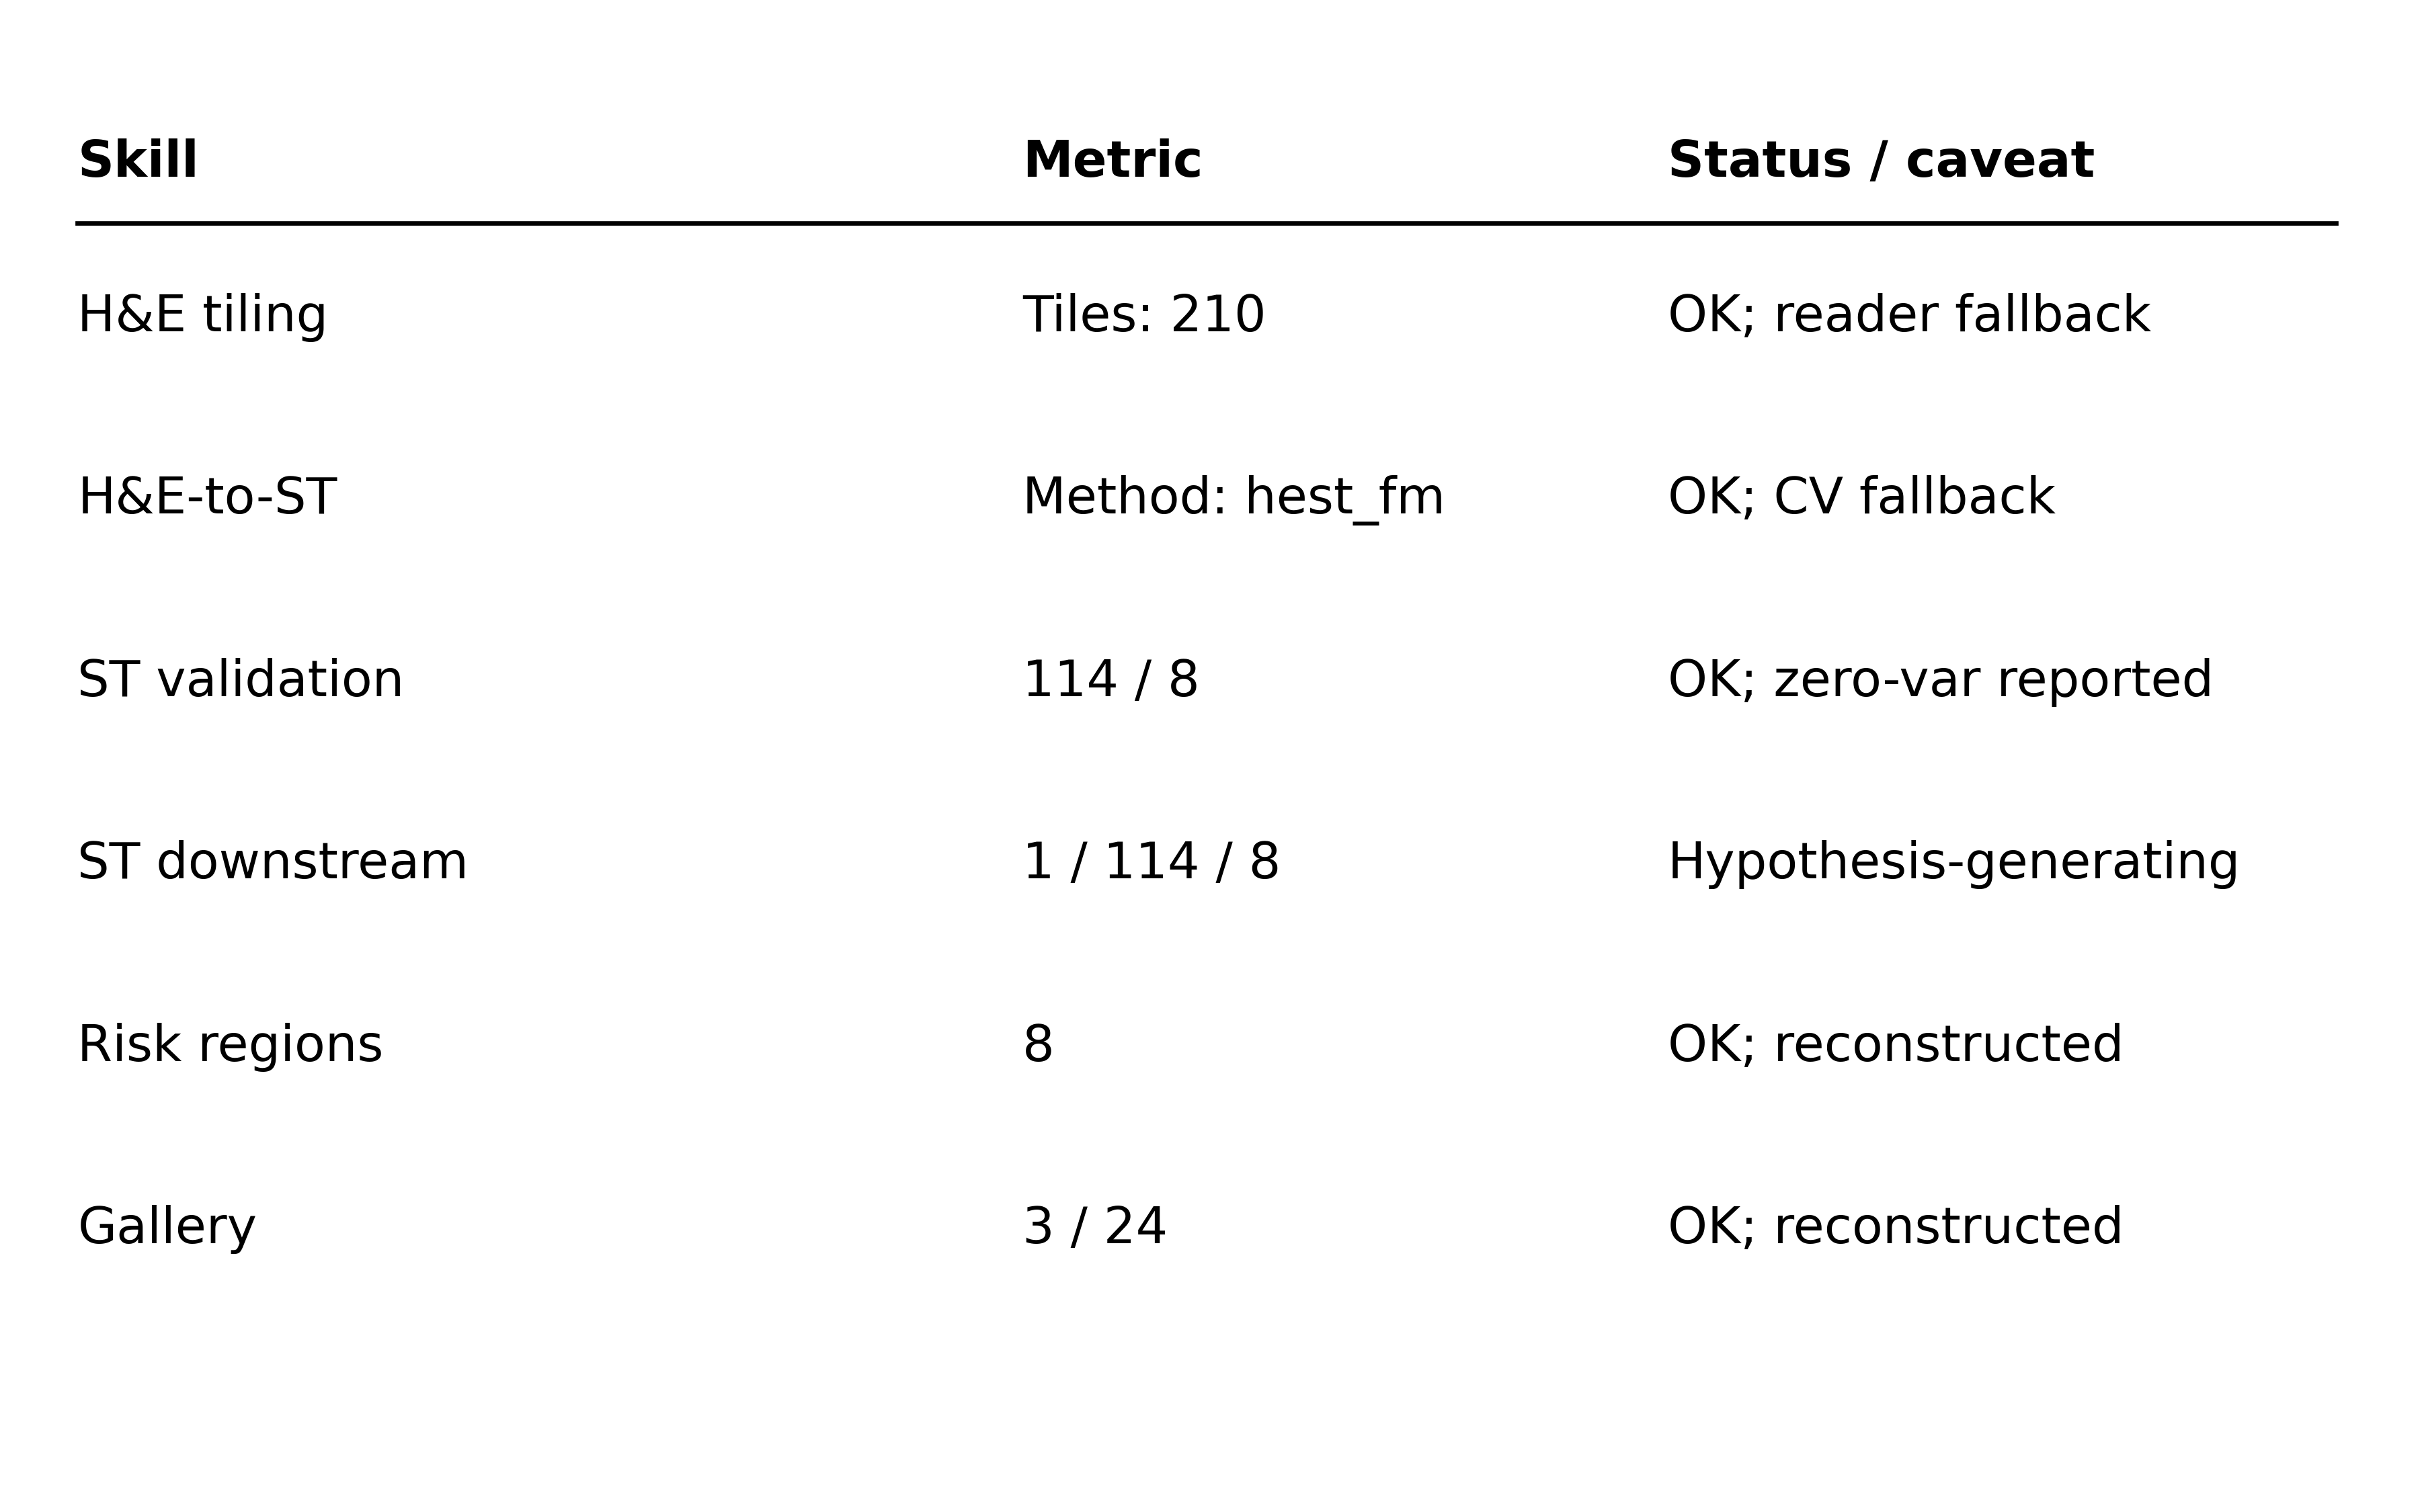

In [7]:
save_panel("supp_skill_iter_D_validation_summary", plot_validation_summary, tables["report"], figsize=PANEL_FIGSIZE)
display(Image(filename=str(PANEL_DIR / "supp_skill_iter_D_validation_summary.png"), width=PANEL_DISPLAY_WIDTH))


## Composite Figure


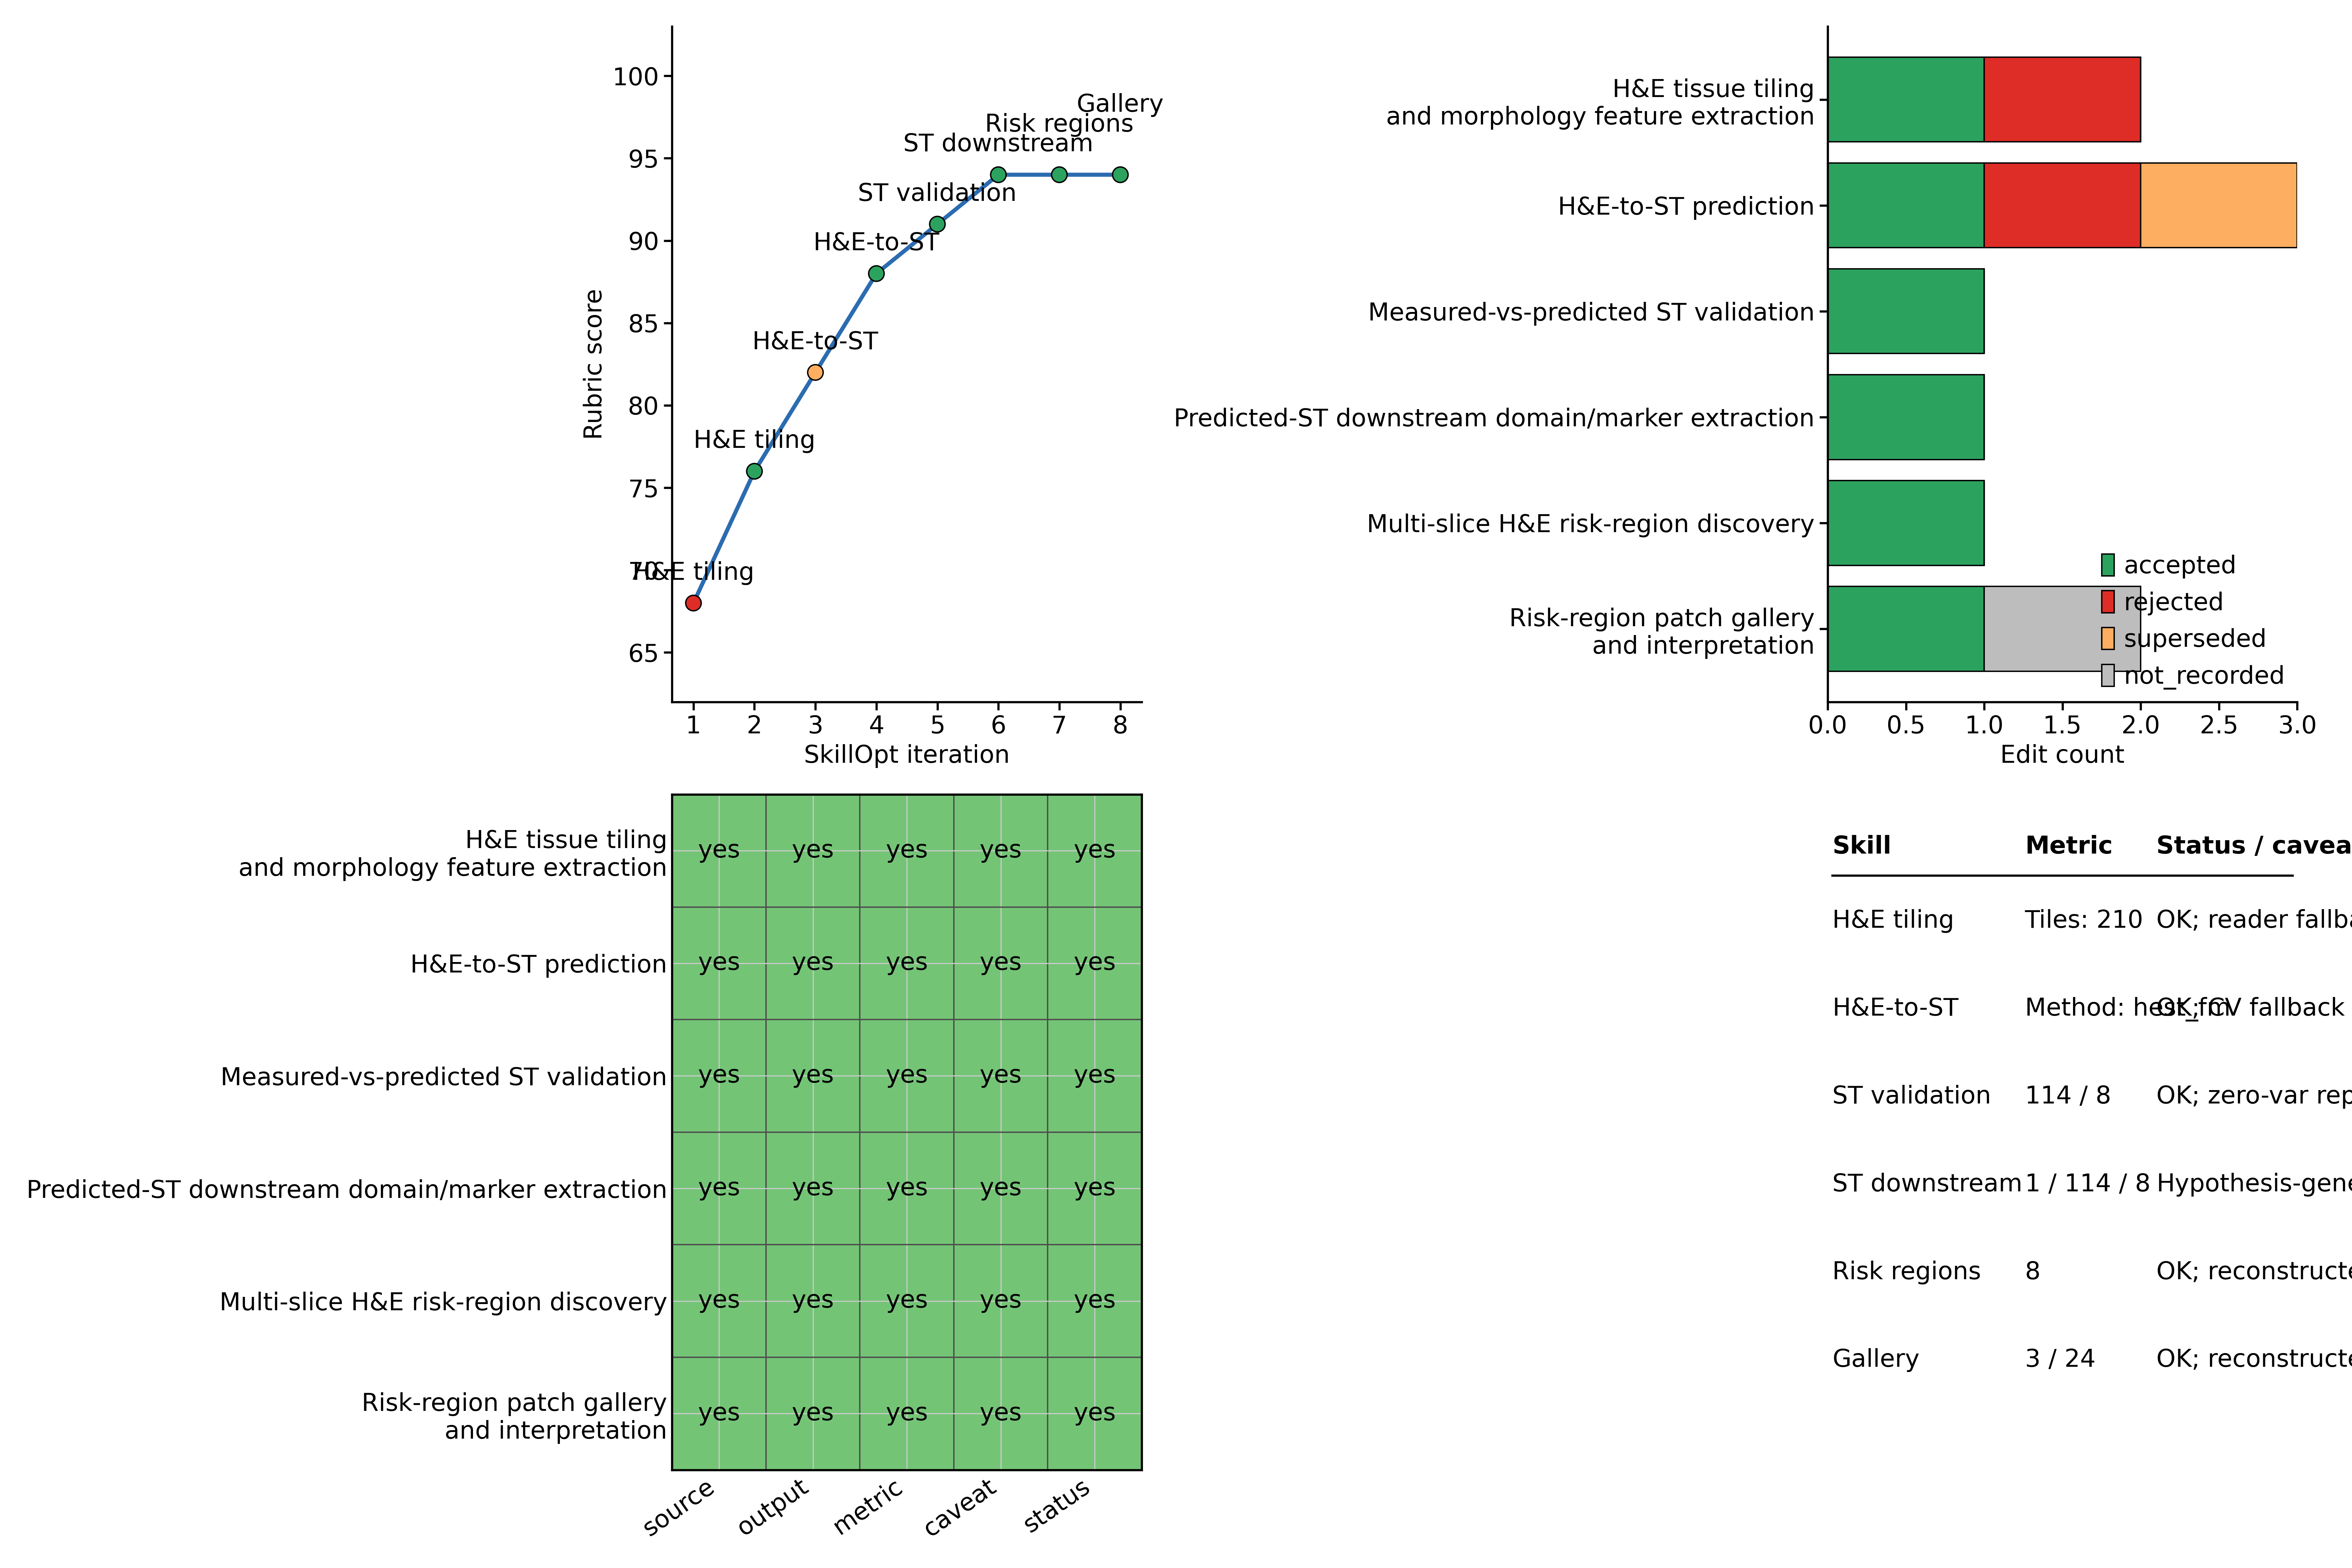

In [8]:
save_composite(tables["trace"], tables["history"], tables["report"], tables["sources"], figsize=COMPOSITE_FIGSIZE)
display(Image(filename=str(FIG_DIR / "supp_fig_lazyslide_skill_iteration_validation.png"), width=COMPOSITE_DISPLAY_WIDTH))
